In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [28]:
# Load dataset
df=pd.read_csv('/content/housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [29]:
# Understand dataset

print("Dataset shape: ",df.shape)
print("\nColumns: \n",df.columns)
print("\nDataset information: \n",df.info)
print("\nStatistical summary: \n",df.describe())

Dataset shape:  (20640, 10)

Columns: 
 Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

Dataset information: 
 <bound method DataFrame.info of        longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0        -122.23     37.88                41.0        880.0           129.0   
1        -122.22     37.86                21.0       7099.0          1106.0   
2        -122.24     37.85                52.0       1467.0           190.0   
3        -122.25     37.85                52.0       1274.0           235.0   
4        -122.25     37.85                52.0       1627.0           280.0   
...          ...       ...                 ...          ...             ...   
20635    -121.09     39.48                25.0       1665.0           374.0   
20636    -121.21     39.49                18.0        697.0   

In [30]:
# Data cleaning and Exploratory data analysis (EDA)

# 1.missing values check

print("Missing values:")
print(df.isnull().sum())

# 2.Duplicate value check

print("\nDuplicate values:")
print(df.duplicated().sum())
df=df.drop_duplicates() # we have remove NUll records because it will not affect on data set
print("Shape after removing duplicates:",df.shape)



Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate values:
0
Shape after removing duplicates: (20640, 10)


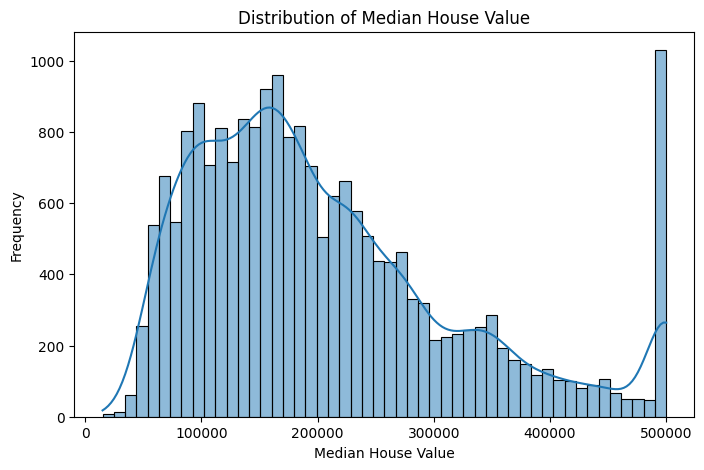

In [31]:
# Visualize target variable

plt.figure(figsize=(8,5))
sns.histplot(df['median_house_value'],bins=50,kde=True)
plt.title('Distribution of Median House Value')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.show()

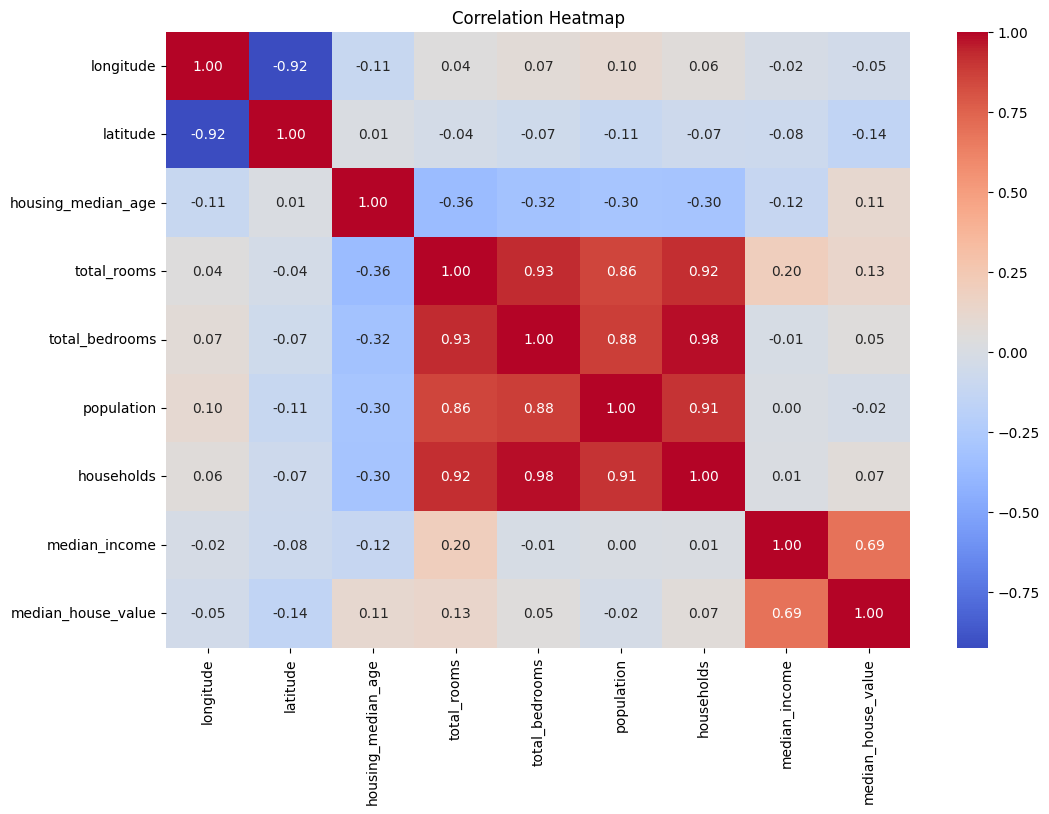

In [32]:
# Correlation heatmap create

plt.figure(figsize=(12,8))
sns.heatmap(df.select_dtypes(include=np.number).corr(),annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [33]:
# Features engineering

df['rooms_per_household'] = (
    df['total_rooms'] / df['households']
)

df['bedrooms_per_room'] = (
    df['total_bedrooms'] / df['total_rooms']
)

df['population_per_household'] = (
    df['population'] / df['households']
)

df['income_per_room'] = (
    df['median_income'] / df['total_rooms']
)

df['income_age_interaction'] = (
    df['median_income'] * df['housing_median_age']
)

df.replace([np.inf, -np.inf], np.nan, inplace=True)

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_per_room,income_age_interaction
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556,0.009460,341.3332
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842,0.001169,174.3294
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260,0.004947,377.3848
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945,0.004429,293.4412
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467,0.002364,200.0024


In [34]:
# Data processing

# Seperate input and target variable
X=df.drop(['median_house_value'],axis=1)
y=df['median_house_value']
print("Input shape:",X.shape)
print("Target shape:",y.shape)


Input shape: (20640, 14)
Target shape: (20640,)


In [35]:
# Differentiate numerical and categorical features

numerical_features=X.select_dtypes(include=np.number).columns.tolist()
categorical_features=X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:",numerical_features)
print("Categorical features:",categorical_features)


Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_room', 'income_age_interaction']
Categorical features: ['ocean_proximity']


In [36]:
# Numeric and categorical data require different pre processing techniques
# So we will create pipelines for them

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)



In [37]:
# Split dataset

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("X_train shape:",X_train.shape)
print("X_test shape:",X_test.shape)



X_train shape: (16512, 14)
X_test shape: (4128, 14)


In [38]:
# 1. OLS-ordinary least squares regression Model

ols_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

ols_model.fit(X_train, y_train)

ols_predictions = ols_model.predict(X_test)

print("OLS Model Training Completed!")

OLS Model Training Completed!


In [39]:
# 2.Ridge regression

ridge_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

ridge_params = {
    'model__alpha': [0.01, 0.1, 1, 10, 100, 500, 1000]
}

ridge_grid = GridSearchCV(
    ridge_model,
    ridge_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

best_ridge = ridge_grid.best_estimator_

ridge_predictions = best_ridge.predict(X_test)

print("Best Ridge Parameters:", ridge_grid.best_params_)

Best Ridge Parameters: {'model__alpha': 1}


In [40]:
# 3.Lasso regression

lasso_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Lasso(max_iter=20000, tol=0.001))
])

lasso_params = {
    'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 500]
}

lasso_grid = GridSearchCV(
    lasso_model,
    lasso_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

lasso_grid.fit(X_train, y_train)

best_lasso = lasso_grid.best_estimator_

lasso_predictions = best_lasso.predict(X_test)

print("Best Lasso Parameters:", lasso_grid.best_params_)

Best Lasso Parameters: {'model__alpha': 500}


In [41]:
# Model evulation

def evaluate_model(y_true, predictions):

    rmse = np.sqrt(mean_squared_error(y_true, predictions))

    mae = mean_absolute_error(y_true, predictions)

    r2 = r2_score(y_true, predictions)

    return rmse, mae, r2

In [42]:
# Comparing models

models = {
    'OLS Regression': ols_predictions,
    'Ridge Regression': ridge_predictions,
    'Lasso Regression': lasso_predictions
}

results = []

for name, predictions in models.items():

    rmse, mae, r2 = evaluate_model(
        y_test, predictions
    )

    results.append({
        'Model': name,
        'RMSE': rmse,
        'MAE': mae,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

display(results_df)

,Model,RMSE,MAE,R2 Score
0,OLS Regression,68941.650035,49322.524731,0.637293
1,Ridge Regression,68949.648495,49328.468635,0.637208
2,Lasso Regression,69094.278217,49272.270058,0.635685


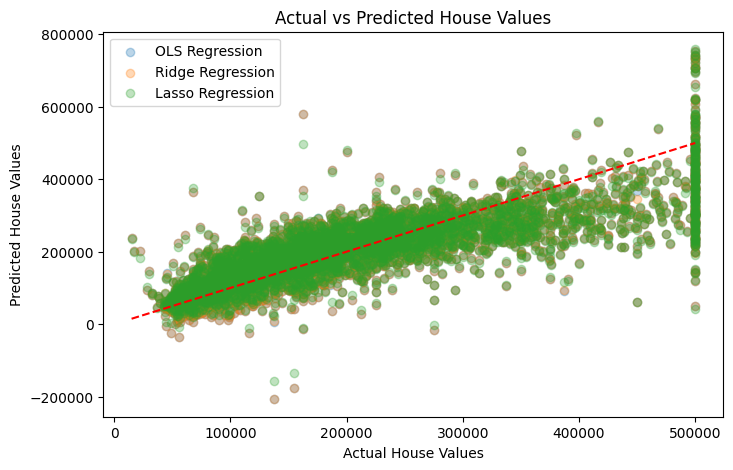

In [43]:
# Residual analysis

# Plot actual vs Predicted values

plt.figure(figsize=(8,5))

for name, predictions in models.items():

    plt.scatter(
        y_test,
        predictions,
        alpha=0.3,
        label=name
    )

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')

plt.title('Actual vs Predicted House Values')

plt.legend()
plt.show()

In [44]:
# Select best model

best_model_name = results_df.loc[
    results_df['RMSE'].idxmin(), 'Model'
]
best_predictions = models[best_model_name]

print("Best Model:", best_model_name)

Best Model: OLS Regression


In [45]:
# Calculate residuals
residuals = y_test - best_predictions

print("First 10 Residual Values:")
print(residuals.head(10))

First 10 Residual Values:
20046     10823.887332
3024     -94098.849769
15663    203968.186812
20484    -62428.903283
9814      13749.752732
13311    -27249.200691
7113     -77466.650292
7668     -48494.674093
18246     80660.238984
5723      17244.258047
Name: median_house_value, dtype: float64


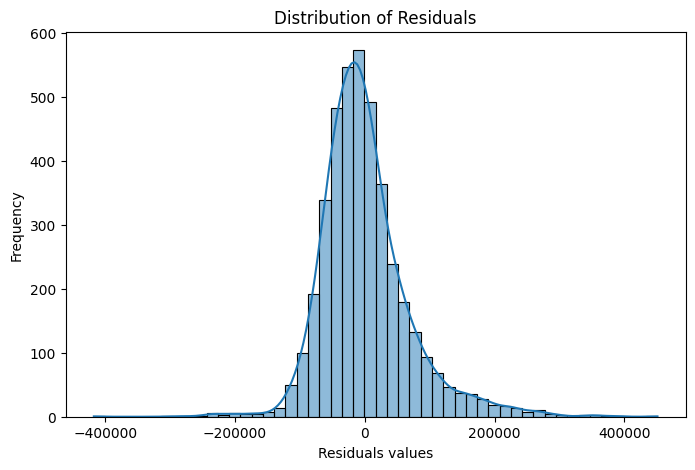

In [46]:
# Plot residual distribution

plt.figure(figsize=(8,5))
sns.histplot(residuals,bins=50,kde=True)
plt.title('Distribution of Residuals')
plt.xlabel('Residuals values')
plt.ylabel('Frequency')
plt.show()

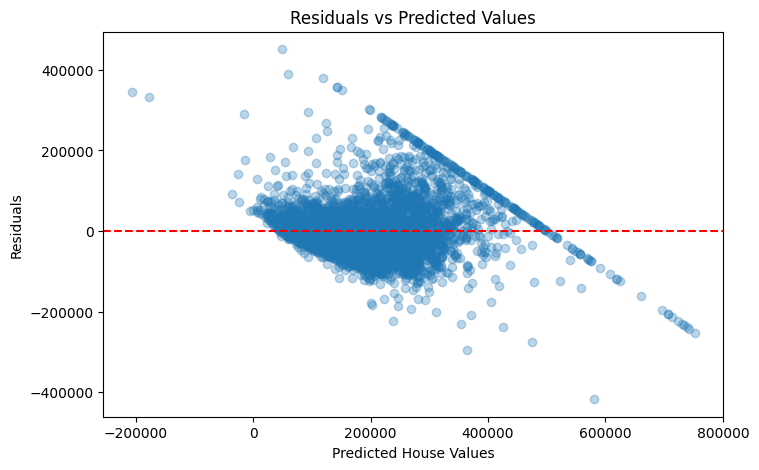

In [47]:
# Plot residuals vs Predicted values

plt.figure(figsize=(8,5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.3
)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted House Values')
plt.ylabel('Residuals')

plt.title('Residuals vs Predicted Values')

plt.show()

In [48]:
# Final model comparison

print("FINAL MODEL COMPARISON")

display(
    results_df.sort_values(by='RMSE')
)
print("\nBest Performing Model:", best_model_name)

print("\nBest Ridge Alpha:", ridge_grid.best_params_)

print("\nBest Lasso Alpha:", lasso_grid.best_params_)

FINAL MODEL COMPARISON


,Model,RMSE,MAE,R2 Score
0,OLS Regression,68941.650035,49322.524731,0.637293
1,Ridge Regression,68949.648495,49328.468635,0.637208
2,Lasso Regression,69094.278217,49272.270058,0.635685



Best Performing Model: OLS Regression

Best Ridge Alpha: {'model__alpha': 1}

Best Lasso Alpha: {'model__alpha': 500}
